# Índice de Prioridad de Intervención en Calidad del Aire (IPICA)
## Priorización municipal de la contaminación por material particulado en Colombia (2020–2024)

**Proyecto — Análisis de Datos I · Maestría en Inteligencia Artificial Aplicada (MIAA)**

---

### Contexto

La contaminación del aire por material particulado (PM2.5 y PM10) es uno de los principales riesgos ambientales para la salud pública. La exposición sostenida a PM2.5 se asocia con enfermedades respiratorias y cardiovasculares y con mortalidad prematura. En Colombia, el Instituto de Hidrología, Meteorología y Estudios Ambientales (IDEAM) consolida las mediciones de las redes de vigilancia de calidad del aire (SVCA) del país.

Frente a una gran cantidad de estaciones y municipios monitoreados, y a unos recursos de gestión e intervención ambiental limitados, es necesario **identificar objetivamente qué municipios requieren mayor atención**. Por eso este proyecto transforma millones de mediciones horarias en un **Índice de Prioridad de Intervención en Calidad del Aire (IPICA)**, que permite una priorización transparente. Como propuesta de uso se plantea el prototipo conceptual **“Air-Prioritizer Dashboard”**, una herramienta visual para consultar los indicadores y apoyar la toma de decisiones en política ambiental.

### Pregunta SMART

> **¿Qué municipios de Colombia presentan la mayor proporción de días con concentraciones de PM2.5 que superan el límite diario recomendado por la OMS (15 µg/m³) durante el periodo 2020–2024, según los datos oficiales del IDEAM, para priorizar acciones gubernamentales de gestión de la calidad del aire?**

### Dataset

- **Fuente:** [Calidad del Aire en Colombia — datos.gov.co (IDEAM)](https://www.datos.gov.co/Ambiente-y-Desarrollo-Sostenible/Calidad-del-Aire-en-Colombia/g4t8-zkc3)
- **Identificador del recurso (Socrata):** `g4t8-zkc3`
- **Volumen:** ~32.7 millones de registros (mediciones horarias), periodo 2020–2024, cobertura nacional.
- **Variables usadas:** estación, municipio, departamento, contaminante (`msfl_code`), concentración estándar, unidad, fecha/hora y coordenadas.
- **Acceso:** descarga directa por API (SODA/Socrata), sin registro.

### Umbrales de referencia

| Referencia | Contaminante | Promedio | Límite |
|---|---|---|---|
| OMS 2021 | PM2.5 | 24 h | 15 µg/m³ |
| OMS 2021 | PM2.5 | anual | 5 µg/m³ |
| OMS 2021 | PM10 | 24 h | 45 µg/m³ |
| OMS 2021 | PM10 | anual | 15 µg/m³ |
| Colombia — Res. 2254 de 2017 | PM2.5 | 24 h | 37 µg/m³ |
| Colombia — Res. 2254 de 2017 | PM2.5 | anual | 25 µg/m³ |
| Colombia — Res. 2254 de 2017 | PM10 | 24 h | 75 µg/m³ |
| Colombia — Res. 2254 de 2017 | PM10 | anual | 50 µg/m³ |


## 1. Importaciones y configuración inicial

In [1]:
import io
import os
import time
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 160)
plt.rcParams['figure.figsize'] = (11, 6)
plt.rcParams['axes.grid'] = True

# Parámetros del análisis
RESOURCE_ID = 'g4t8-zkc3'
BASE_URL = f'https://www.datos.gov.co/resource/{RESOURCE_ID}.csv'

# El recurso está ordenado cronológicamente, así que se descargan tramos a
# distintos offsets para cubrir 2020-2024. De cada tramo se toman FILAS_POR_ANIO
# filas crudas (todos los contaminantes); luego se filtra a PM2.5 / PM10.
# Offsets aproximados de inicio de cada año en el recurso:
OFFSETS_ANIO = {
    2020: 1_000_000,
    2021: 5_000_000,
    2022: 15_000_000,
    2023: 22_000_000,
    2024: 29_000_000,
}
FILAS_POR_ANIO = 500_000   # filas crudas por año (ajustable según memoria)
PAGE_SIZE = 25_000         # tamaño de página de la API (estable)

# Guías OMS 2021 (µg/m³)
OMS_PM25_DIARIO = 15
OMS_PM25_ANUAL = 5
OMS_PM10_DIARIO = 45
OMS_PM10_ANUAL = 15

# Norma nacional, Resolución 2254 de 2017 (µg/m³)
COL_PM25_DIARIO = 37
COL_PM25_ANUAL = 25
COL_PM10_DIARIO = 75
COL_PM10_ANUAL = 50

_total = FILAS_POR_ANIO * len(OFFSETS_ANIO)
print(f'Se traerán ~{FILAS_POR_ANIO:,} filas por año para {list(OFFSETS_ANIO)} '
      f'(~{_total:,} filas crudas) en páginas de {PAGE_SIZE:,}.')

Se traerán ~500,000 filas por año para [2020, 2021, 2022, 2023, 2024] (~2,500,000 filas crudas) en páginas de 25,000.


## 2. Descarga de los datos desde la API del IDEAM

El recurso completo tiene ~32.7 millones de filas y está ordenado cronológicamente. Para cubrir el periodo 2020-2024 se descargan **tramos a distintos offsets** (uno por año), seleccionando solo las columnas necesarias. El filtrado por contaminante se hace después en pandas. El resultado se guarda en un CSV local; si ese archivo ya existe pero tiene un número de filas distinto al solicitado, se vuelve a descargar automáticamente.

In [2]:
COLS = [
    'estacion_id', 'nombre_est', 'msfl_code', 'med_concentracion_estandar',
    'med_fecha_inicio', 'sigla_unidad', 'municipio', 'departamento',
    'codigo_municipio', 'codigo_departamento', 'latitud', 'longitud', 'tipo_estacion'
]

ARCHIVO_CRUDO = 'aire_crudo.csv'


def descargar_pagina(cols, limit, offset, intentos=4):
    params = {
        '$select': ','.join(cols),
        '$order': ':id',
        '$limit': limit,
        '$offset': offset,
    }
    for intento in range(1, intentos + 1):
        try:
            r = requests.get(BASE_URL, params=params, timeout=120)
            r.raise_for_status()
            return pd.read_csv(io.StringIO(r.text), low_memory=False)
        except Exception as e:
            espera = 5 * intento
            print(f'  Error en offset {offset:,} (intento {intento}/{intentos}): {e}. '
                  f'Reintento en {espera}s.')
            time.sleep(espera)
    raise RuntimeError(f'No se pudo descargar la página en offset {offset}')


def descargar_tramo(offset_inicio, n_filas):
    """Descarga n_filas crudas de forma paginada a partir de un offset."""
    partes_tramo = []
    descargadas = 0
    offset = offset_inicio
    while descargadas < n_filas:
        page_limit = min(PAGE_SIZE, n_filas - descargadas)
        pagina = descargar_pagina(COLS, page_limit, offset)
        if len(pagina) == 0:
            break
        partes_tramo.append(pagina)
        descargadas += len(pagina)
        offset += len(pagina)
        if len(pagina) < page_limit:
            break
    if not partes_tramo:
        return pd.DataFrame(columns=COLS)
    return pd.concat(partes_tramo, ignore_index=True)


FILAS_OBJETIVO = FILAS_POR_ANIO * len(OFFSETS_ANIO)

# Reutiliza el CSV solo si tiene el numero de filas esperado; si no, re-descarga.
usar_cache = False
if os.path.exists(ARCHIVO_CRUDO):
    df_crudo = pd.read_csv(ARCHIVO_CRUDO, low_memory=False)
    if len(df_crudo) == FILAS_OBJETIVO:
        usar_cache = True
        print(f'Cargando datos existentes: {ARCHIVO_CRUDO} ({len(df_crudo):,} filas)')
    else:
        print(f'El archivo {ARCHIVO_CRUDO} tiene {len(df_crudo):,} filas '
              f'(se esperaban {FILAS_OBJETIVO:,}). Se vuelve a descargar.')

if not usar_cache:
    partes = []
    t0 = time.time()
    for anio, offset in OFFSETS_ANIO.items():
        print(f'Año {anio} (offset {offset:,})...')
        tramo = descargar_tramo(offset, FILAS_POR_ANIO)
        partes.append(tramo)
        print(f'  {len(tramo):,} filas ({time.time() - t0:0.1f}s)')
    df_crudo = pd.concat(partes, ignore_index=True)
    df_crudo.to_csv(ARCHIVO_CRUDO, index=False)
    print(f'\n{len(df_crudo):,} filas guardadas en {ARCHIVO_CRUDO}.')

df_crudo.head()

Año 2020 (offset 1,000,000)...
  500,000 filas (85.1s)
Año 2021 (offset 5,000,000)...
  500,000 filas (198.3s)
Año 2022 (offset 15,000,000)...
  500,000 filas (398.6s)
Año 2023 (offset 22,000,000)...
  Error en offset 22,350,000 (intento 1/4): ("Connection broken: ConnectionResetError(104, 'Connection reset by peer')", ConnectionResetError(104, 'Connection reset by peer')). Reintento en 5s.
  500,000 filas (683.2s)
Año 2024 (offset 29,000,000)...
  500,000 filas (1082.2s)

2,500,000 filas guardadas en aire_crudo.csv.


,estacion_id,nombre_est,msfl_code,med_concentracion_estandar,med_fecha_inicio,sigla_unidad,municipio,departamento,codigo_municipio,codigo_departamento,latitud,longitud,tipo_estacion
0,31838,HOT,DViento,109.20,2020-12-16T10:00:00.000,°,Yarumal,Antioquia,5887,5,6.963466,-75.418262,Indicativa
1,8205,FLORIDA,O3,52.37,2020-11-13T15:00:00.000,ug/m3,Floridablanca,Santander,68276,68,7.072186,-73.106089,Fija
2,30732,TANQUES LA YE,O3,74.16,2020-06-01T14:00:00.000,ug/m3,Medellín,Antioquia,5001,5,6.182572,-75.550720,Fija
3,30733,TRÁFICO SUR,PLiquida,0.00,2020-09-20T21:00:00.000,mm,Sabaneta,Antioquia,5631,5,6.152219,-75.627563,Fija
4,8986,LA FLORA,DViento,62.90,2020-05-10T19:00:00.000,°,Santiago de Cali,Valle del Cauca,76001,76,3.488218,-76.518058,Fija


In [3]:
print('Dimensiones:', df_crudo.shape)
print()
print(df_crudo['msfl_code'].value_counts())

Dimensiones: (2500000, 13)

msfl_code
PM2.5       294078
DViento     253773
PM10        251249
VViento     232646
PLiquida    198164
TAire10     179208
P           178825
HAire10     132885
O3          121090
SO2         116718
NO2         115745
TAire2       92321
CO           92197
RGlobal      87595
HAire2       71992
NO           63370
RUVb         18136
PST              8
Name: count, dtype: int64


## 3. Limpieza y preparación

Se conservan únicamente PM2.5 y PM10 (material particulado, en µg/m³), se convierten los tipos, se descartan nulos y valores inválidos, y se extraen la fecha y el año.

In [4]:
df = df_crudo[df_crudo['msfl_code'].isin(['PM2.5', 'PM10'])].copy()

df['med_concentracion_estandar'] = pd.to_numeric(
    df['med_concentracion_estandar'], errors='coerce')
df['med_fecha_inicio'] = pd.to_datetime(df['med_fecha_inicio'], errors='coerce')

antes = len(df)
df = df.dropna(subset=['med_concentracion_estandar', 'med_fecha_inicio', 'municipio'])
df = df[(df['med_concentracion_estandar'] >= 0) & (df['med_concentracion_estandar'] <= 1000)]
despues = len(df)

df['fecha'] = df['med_fecha_inicio'].dt.date
df['anio'] = df['med_fecha_inicio'].dt.year

print(f'Filas PM2.5/PM10 antes de limpiar: {antes:,}')
print(f'Filas tras limpieza:               {despues:,}')
print()
print(df['msfl_code'].value_counts())
print()
print('Rango temporal:', df['med_fecha_inicio'].min(), '->', df['med_fecha_inicio'].max())
print('Municipios:', df['municipio'].nunique(), '| Estaciones:', df['estacion_id'].nunique())

Filas PM2.5/PM10 antes de limpiar: 545,327
Filas tras limpieza:               545,327

msfl_code
PM2.5    294078
PM10     251249
Name: count, dtype: int64

Rango temporal: 2020-01-01 00:00:00 -> 2024-12-31 23:00:00
Municipios: 125 | Estaciones: 381


## 4. Análisis exploratorio — Distribución del material particulado

In [5]:
resumen = (df.groupby('msfl_code')['med_concentracion_estandar']
             .describe()[['count', 'mean', 'std', 'min', '50%', 'max']]
             .rename(columns={'50%': 'mediana'}))
resumen

,count,mean,std,min,mediana,max
msfl_code,,,,,,
PM10,251249.0,29.957421,21.334170,0.0,25.00,495.82
PM2.5,294078.0,13.931099,10.030114,0.0,11.58,175.30


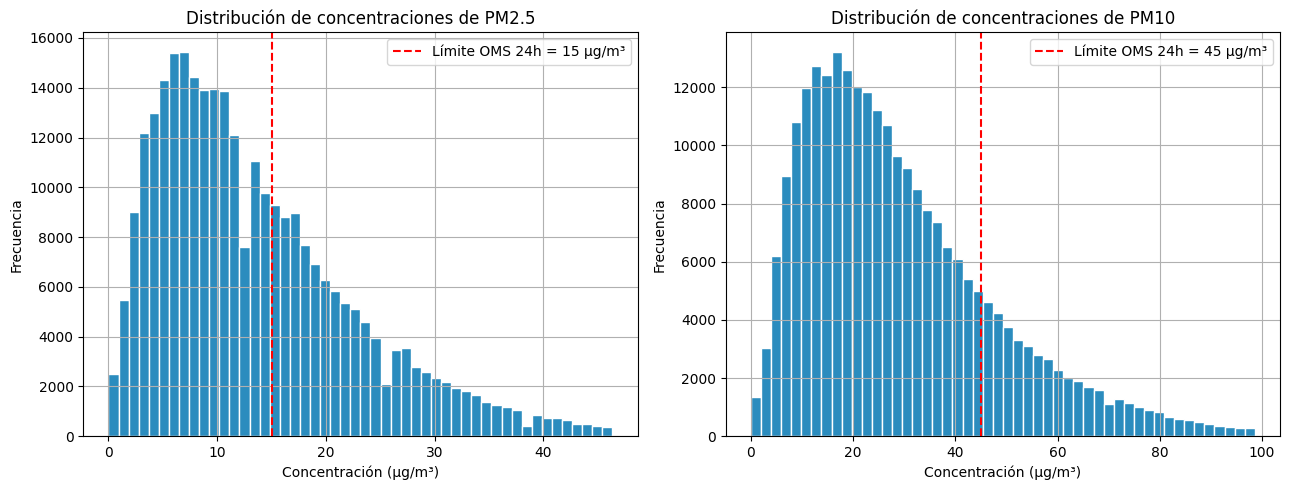

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, cont, umbral in zip(axes, ['PM2.5', 'PM10'], [OMS_PM25_DIARIO, OMS_PM10_DIARIO]):
    serie = df.loc[df['msfl_code'] == cont, 'med_concentracion_estandar']
    serie = serie[serie <= serie.quantile(0.99)]
    ax.hist(serie, bins=50, color='#2b8cbe', edgecolor='white')
    ax.axvline(umbral, color='red', linestyle='--', label=f'Límite OMS 24h = {umbral} µg/m³')
    ax.set_title(f'Distribución de concentraciones de {cont}')
    ax.set_xlabel('Concentración (µg/m³)')
    ax.set_ylabel('Frecuencia')
    ax.legend()
plt.tight_layout()
plt.show()

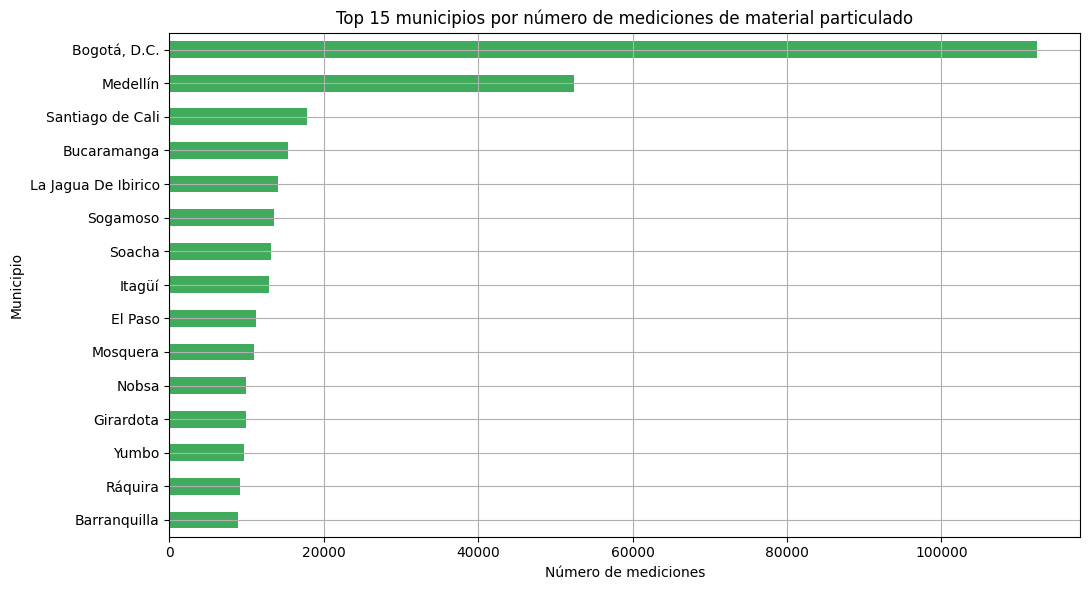

In [7]:
cobertura = (df.groupby('municipio')['med_concentracion_estandar']
               .count().sort_values(ascending=False).head(15))
cobertura.sort_values().plot(kind='barh', color='#41ab5d')
plt.title('Top 15 municipios por número de mediciones de material particulado')
plt.xlabel('Número de mediciones')
plt.ylabel('Municipio')
plt.tight_layout()
plt.show()

## 5. Agregación diaria por estación

El índice se basa en excedencias de los límites diarios, por lo que se promedian las mediciones horarias a concentración media diaria por estación y contaminante.

In [8]:
diario = (df.groupby(['municipio', 'departamento', 'estacion_id',
                      'msfl_code', 'fecha', 'anio'])['med_concentracion_estandar']
            .mean().reset_index()
            .rename(columns={'med_concentracion_estandar': 'conc_diaria'}))
print('Registros diarios:', len(diario))
diario.head()

Registros diarios: 262906


,municipio,departamento,estacion_id,msfl_code,fecha,anio,conc_diaria
0,Agustín Codazzi,Cesar,30691,PM10,2020-02-16,2020,39.50
1,Agustín Codazzi,Cesar,30691,PM10,2020-02-19,2020,42.29
2,Agustín Codazzi,Cesar,30691,PM10,2020-05-22,2020,12.75
3,Agustín Codazzi,Cesar,30691,PM10,2020-05-25,2020,14.50
4,Agustín Codazzi,Cesar,30691,PM10,2020-08-17,2020,19.46


## 6. Indicadores de excedencia por municipio (PM2.5)

Para cada municipio se calcula, sobre sus días-estación de PM2.5: el porcentaje de días que exceden el límite diario OMS (15 µg/m³) y el de la norma colombiana (37 µg/m³), la concentración media diaria, el percentil 95 (severidad de los episodios) y el máximo diario.

In [9]:
pm25 = diario[diario['msfl_code'] == 'PM2.5'].copy()
pm25['excede_oms'] = pm25['conc_diaria'] > OMS_PM25_DIARIO
pm25['excede_col'] = pm25['conc_diaria'] > COL_PM25_DIARIO

# Mínimo de días observados para que un municipio sea comparable
MIN_DIAS = 30

kpi = (pm25.groupby('municipio')
            .agg(dias_observados=('conc_diaria', 'size'),
                 pct_exc_oms=('excede_oms', 'mean'),
                 pct_exc_col=('excede_col', 'mean'),
                 conc_media=('conc_diaria', 'mean'),
                 conc_p95=('conc_diaria', lambda s: np.percentile(s, 95)),
                 conc_max=('conc_diaria', 'max'))
            .reset_index())
kpi[['pct_exc_oms', 'pct_exc_col']] *= 100

kpi = kpi[kpi['dias_observados'] >= MIN_DIAS].copy()
print(f'Municipios comparables (>= {MIN_DIAS} días con PM2.5):', len(kpi))
kpi.sort_values('pct_exc_oms', ascending=False).head(10)

Municipios comparables (>= 30 días con PM2.5): 96


,municipio,dias_observados,pct_exc_oms,pct_exc_col,conc_media,conc_p95,conc_max
2,Amagá,634,88.958991,17.981073,27.739012,47.087500,71.00
33,Floridablanca,105,72.380952,20.952381,26.192952,60.840000,69.50
75,Sabaneta,2415,64.886128,6.625259,20.067014,39.000000,58.00
42,Itagüí,3029,61.604490,4.423902,18.941791,36.000000,70.00
52,Maceo,75,58.666667,0.000000,16.714000,26.433333,34.00
58,Medellín,18067,57.574583,3.415066,17.942922,34.923333,89.00
82,Santander De Quilichao,65,56.923077,1.538462,16.115962,31.326000,39.15
48,La Estrella,1685,54.480712,1.661721,17.088786,32.000000,60.00
53,Madrid,1072,54.291045,3.917910,17.368827,35.235000,56.50
15,Caldas,2123,54.121526,2.025436,16.832994,31.294000,52.30


## 7. Índice de Prioridad de Intervención en Calidad del Aire (IPICA)

Los indicadores se combinan en un índice único. Cada componente se normaliza al rango [0, 1] (min–max) y se pondera según su importancia:

| Componente | Qué mide | Peso |
|---|---|---|
| % días que exceden OMS | exposición de la población | 0.40 |
| Concentración media | carga crónica | 0.25 |
| Percentil 95 | severidad de los episodios | 0.20 |
| % días que exceden norma Colombia | incumplimiento normativo | 0.15 |

El IPICA resultante se escala de 0 a 100.

In [10]:
def minmax(s):
    rango = s.max() - s.min()
    if rango == 0:
        return pd.Series(0.0, index=s.index)
    return (s - s.min()) / rango

pesos = {
    'pct_exc_oms': 0.40,
    'conc_media': 0.25,
    'conc_p95': 0.20,
    'pct_exc_col': 0.15,
}

for col in pesos:
    kpi[f'{col}_norm'] = minmax(kpi[col])

kpi['IPICA'] = sum(kpi[f'{col}_norm'] * w for col, w in pesos.items())
kpi['IPICA_100'] = (minmax(kpi['IPICA']) * 100).round(1)

ranking = kpi.sort_values('IPICA_100', ascending=False).reset_index(drop=True)
ranking.index += 1
ranking.index.name = 'Ranking'

cols_mostrar = ['municipio', 'dias_observados', 'pct_exc_oms', 'pct_exc_col',
                'conc_media', 'conc_p95', 'conc_max', 'IPICA_100']
ranking[cols_mostrar].head(15).round(2)

,municipio,dias_observados,pct_exc_oms,pct_exc_col,conc_media,conc_p95,conc_max,IPICA_100
Ranking,,,,,,,,
1,Amagá,634,88.96,17.98,27.74,47.09,71.00,100.0
2,Floridablanca,105,72.38,20.95,26.19,60.84,69.50,98.2
3,Sabaneta,2415,64.89,6.63,20.07,39.00,58.00,66.7
4,Itagüí,3029,61.60,4.42,18.94,36.00,70.00,60.8
5,San José de Cúcuta,953,44.70,8.92,17.20,46.09,74.23,58.3
6,Medellín,18067,57.57,3.42,17.94,34.92,89.00,56.4
7,Girón,221,51.13,5.88,17.28,37.40,47.90,55.4
8,Madrid,1072,54.29,3.92,17.37,35.23,56.50,54.6
9,Soacha,3173,44.37,5.70,16.56,37.88,145.10,51.3


## 8. Visualización del ranking de prioridad

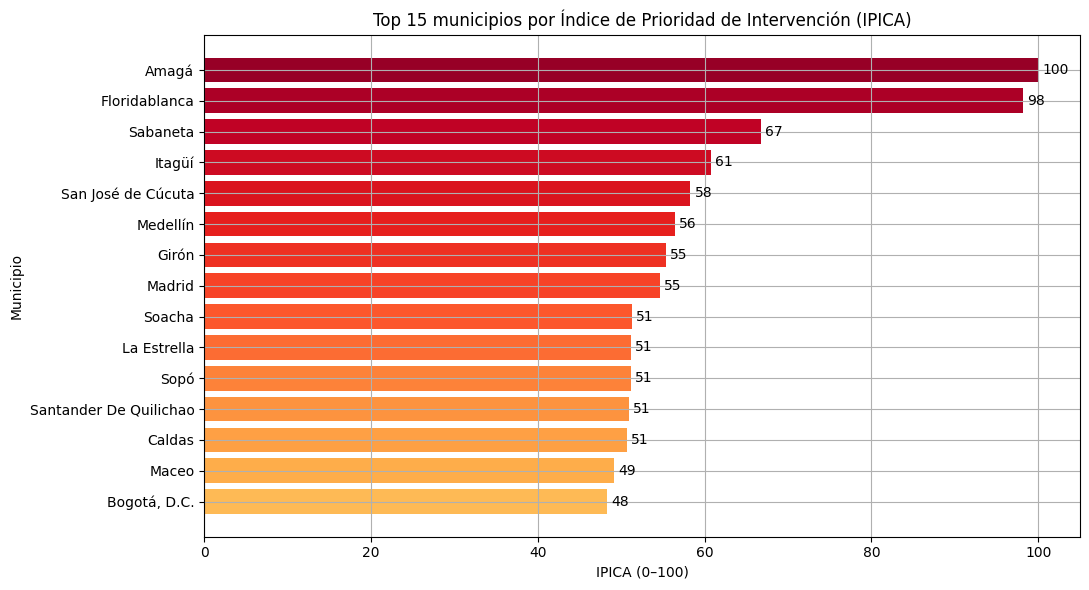

In [11]:
top = ranking.head(15).iloc[::-1]
colores = plt.cm.YlOrRd(np.linspace(0.35, 0.95, len(top)))
plt.barh(top['municipio'], top['IPICA_100'], color=colores)
plt.title('Top 15 municipios por Índice de Prioridad de Intervención (IPICA)')
plt.xlabel('IPICA (0–100)')
plt.ylabel('Municipio')
for y, v in enumerate(top['IPICA_100']):
    plt.text(v + 0.5, y, f'{v:.0f}', va='center')
plt.tight_layout()
plt.show()

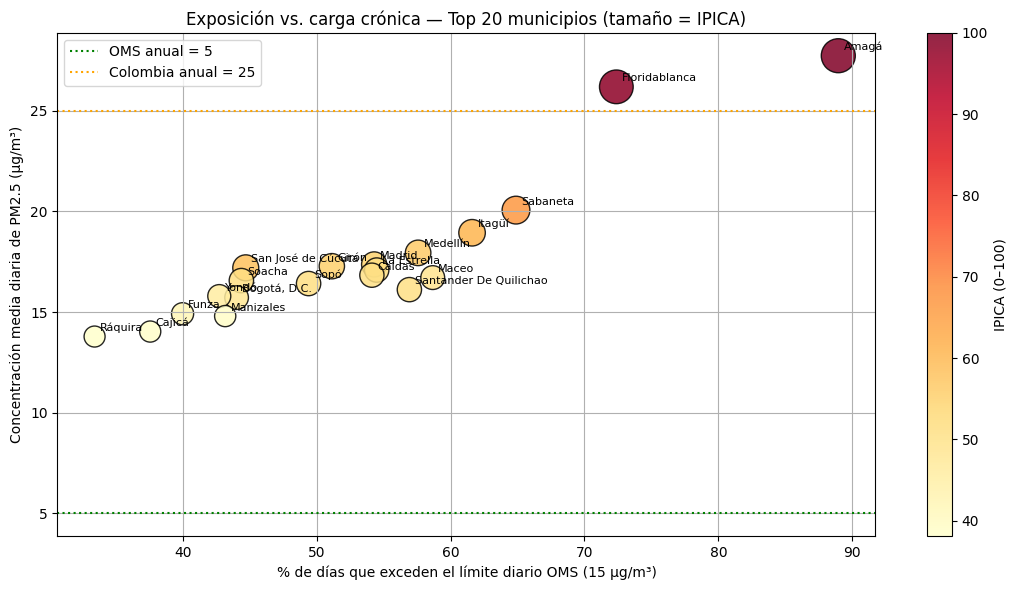

In [12]:
top20 = ranking.head(20)
plt.scatter(top20['pct_exc_oms'], top20['conc_media'],
            s=top20['IPICA_100'] * 6, c=top20['IPICA_100'],
            cmap='YlOrRd', edgecolor='black', alpha=0.85)
for _, r in top20.iterrows():
    plt.annotate(r['municipio'], (r['pct_exc_oms'], r['conc_media']),
                 fontsize=8, xytext=(4, 4), textcoords='offset points')
plt.colorbar(label='IPICA (0–100)')
plt.axhline(OMS_PM25_ANUAL, color='green', linestyle=':', label=f'OMS anual = {OMS_PM25_ANUAL}')
plt.axhline(COL_PM25_ANUAL, color='orange', linestyle=':', label=f'Colombia anual = {COL_PM25_ANUAL}')
plt.xlabel('% de días que exceden el límite diario OMS (15 µg/m³)')
plt.ylabel('Concentración media diaria de PM2.5 (µg/m³)')
plt.title('Exposición vs. carga crónica — Top 20 municipios (tamaño = IPICA)')
plt.legend()
plt.tight_layout()
plt.show()

## 9. Evolución temporal del material particulado

Promedio anual de PM2.5 a nivel nacional frente a los umbrales anuales de referencia.

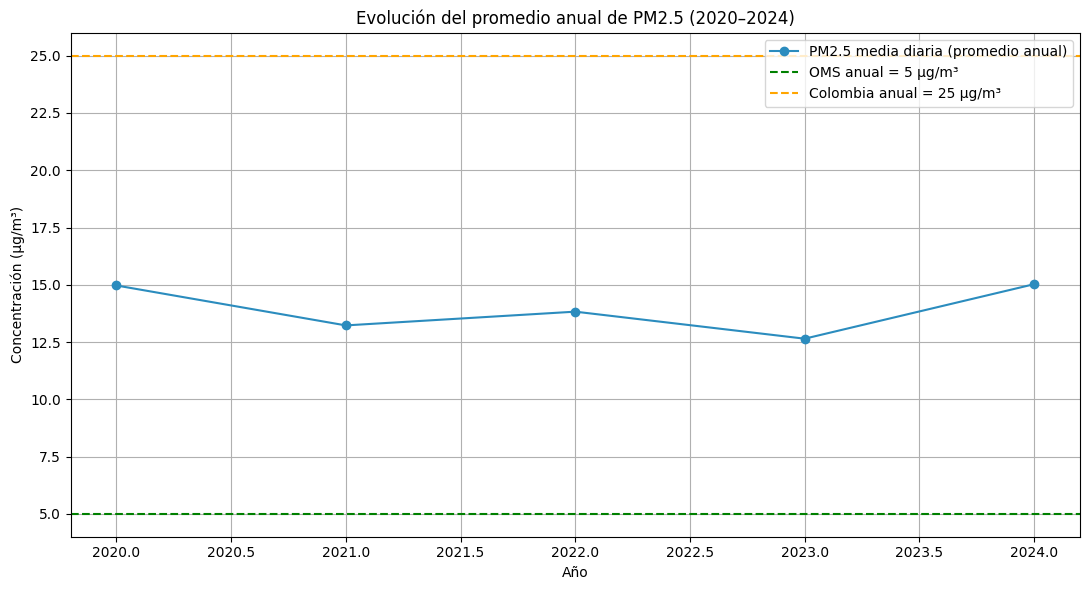

In [13]:
serie_anual = pm25.groupby('anio')['conc_diaria'].mean()
serie_anual.plot(marker='o', color='#2b8cbe', label='PM2.5 media diaria (promedio anual)')
plt.axhline(OMS_PM25_ANUAL, color='green', linestyle='--', label=f'OMS anual = {OMS_PM25_ANUAL} µg/m³')
plt.axhline(COL_PM25_ANUAL, color='orange', linestyle='--', label=f'Colombia anual = {COL_PM25_ANUAL} µg/m³')
plt.title('Evolución del promedio anual de PM2.5 (2020–2024)')
plt.xlabel('Año')
plt.ylabel('Concentración (µg/m³)')
plt.legend()
plt.tight_layout()
plt.show()

## 10. Exportar resultados

Se guarda la tabla de ranking para alimentar el prototipo conceptual Air-Prioritizer Dashboard y como insumo de la sustentación.

In [14]:
salida = ranking[cols_mostrar].copy()
salida.to_csv('ipica_ranking_municipios.csv')
print('Ranking exportado a ipica_ranking_municipios.csv')
salida.head(20).round(2)

Ranking exportado a ipica_ranking_municipios.csv


,municipio,dias_observados,pct_exc_oms,pct_exc_col,conc_media,conc_p95,conc_max,IPICA_100
Ranking,,,,,,,,
1,Amagá,634,88.96,17.98,27.74,47.09,71.00,100.0
2,Floridablanca,105,72.38,20.95,26.19,60.84,69.50,98.2
3,Sabaneta,2415,64.89,6.63,20.07,39.00,58.00,66.7
4,Itagüí,3029,61.60,4.42,18.94,36.00,70.00,60.8
5,San José de Cúcuta,953,44.70,8.92,17.20,46.09,74.23,58.3
6,Medellín,18067,57.57,3.42,17.94,34.92,89.00,56.4
7,Girón,221,51.13,5.88,17.28,37.40,47.90,55.4
8,Madrid,1072,54.29,3.92,17.37,35.23,56.50,54.6
9,Soacha,3173,44.37,5.70,16.56,37.88,145.10,51.3


## 11. Conclusiones

- **Priorización:** El IPICA ordena los municipios según una combinación objetiva de exposición (% de días sobre el límite OMS), carga crónica (concentración media), severidad de los episodios (percentil 95) e incumplimiento normativo (% sobre la norma colombiana). Sobre 545.327 mediciones de material particulado (2020-2024) de 125 municipios y 381 estaciones, encabezan la priorización **Amagá** (IPICA 100) y **Floridablanca** (IPICA 98,2). Destaca una fuerte concentración de municipios prioritarios en el **Valle de Aburrá** (Amagá, Sabaneta, Itagüí, Medellín, Girón, La Estrella), consistente con su condición de valle con alta densidad industrial y vehicular.

- **Brecha OMS vs. norma colombiana:** La norma nacional es considerablemente más laxa que la guía OMS. Amagá, por ejemplo, excede el límite diario OMS (15 µg/m³) el **88,96 %** de los días observados, pero solo supera el límite colombiano (37 µg/m³) el **17,98 %**. Es decir, un municipio puede "cumplir" la norma nacional la mayor parte del tiempo y aun así exponer a su población a niveles no recomendados por la OMS.

- **Evolución temporal:** El promedio anual de PM2.5 se mantuvo durante todo el periodo por encima de la guía OMS (5 µg/m³) y por debajo de la norma colombiana (25 µg/m³). Partió de ~15 µg/m³ en 2020, descendió hasta su mínimo en 2023 (~12,6 µg/m³) y repuntó en 2024 (~15 µg/m³), lo que sugiere que las mejoras observadas no se han consolidado.

- **Cobertura de monitoreo:** El análisis depende de las estaciones disponibles; de los 125 municipios con datos, 96 alcanzaron el mínimo de días para ser comparables. Los municipios sin estaciones o con pocos días observados quedan fuera del ranking.

- **Uso propuesto:** El prototipo conceptual Air-Prioritizer Dashboard permitiría a las autoridades ambientales consultar estos indicadores y focalizar recursos de monitoreo e intervención en los municipios de mayor IPICA.

### Limitaciones

- Se trabajó con una muestra por tramos del recurso (parámetro `FILAS_POR_ANIO` por cada año 2020-2024); ampliarla aumenta la representatividad.
- No se integraron variables meteorológicas, de población ni de fuentes de emisión; el índice es de priorización por exposición, no un modelo causal.
- La calidad y continuidad del monitoreo varía entre estaciones y periodos, y la cobertura de estaciones no es homogénea entre regiones del país.
